# Goal: Execute multiple independent tasks simultaneously and combine their results.

# Project: Startup Idea Research Agent 

In [83]:
from langgraph.graph import StateGraph , START,END
from pydantic import BaseModel , Field
from langchain_groq import ChatGroq

In [84]:
llm = ChatGroq(model="openai/gpt-oss-120b")

In [85]:
class State(BaseModel ):
    input_topic : str =""
    problem_and_demand:str =""
    target_customer:str =""
    competitors_and_alternatives:str =""
    Execution_and_legal_basics:str  =""
    Pricing_and_Business_Model:str  =""
    final_report:str  =""

In [86]:
def inpTopic(state):
    x = input("Explain your Starup Idea in detail")
    return {
        "input_topic": x
    }

In [87]:
def ProblemAndDemand(state):
    inp_text = state.input_topic
    response = llm.invoke(f"You are a Startup researcher, research on this topic : {inp_text} on the basis of Problem and demand")
    return {
        "problem_and_demand": response.content
        }

In [88]:
def Targetcustomer(state):
    inp_text = state.input_topic
    response = llm.invoke(f"You are a Startup researcher, research on this topic : {inp_text} on the basis of Target customer")
    return {
        "target_customer": response.content
        }

In [89]:
def Competitorsandalternatives(state):
    inp_text = state.input_topic
    response = llm.invoke(f"You are a Startup researcher, research on this topic : {inp_text} on the basis of Competitors and alternatives")
    return {
        "competitors_and_alternatives": response.content
        }

In [90]:
def ExecutionAndlegalbasics(state):
    inp_text = state.input_topic
    response = llm.invoke(f"You are a Startup researcher, research on this topic : {inp_text} on the basis of Execution and legal basics")
    return {
        "Execution_and_legal_basics": response.content
        }

In [91]:
def PricingBusinessModel(state):
    inp_text = state.input_topic
    response = llm.invoke(f"You are a Startup researcher, research on this topic : {inp_text} on the basis of Pricing & Business Model")
    return {
        "Pricing_and_Business_Model": response.content
        }

In [92]:
def final_report(state) -> dict:
    separator = "=" * 50

    final = f"""
{separator} 
            Startup ANALYSIS
{separator}

1. PROBLEM AND DEMAND
{state.problem_and_demand}

{separator}

2. Target customer
{state.target_customer}

{separator}

3. Competitors and alternatives
{state.competitors_and_alternatives}

{separator}

4. Execution and legal basics
{state.Execution_and_legal_basics}

{separator}

5. Pricing & Business Model
{state.Pricing_and_Business_Model}

{separator}
                END OF REPORT
{separator}
                """
    # print(final)
    return {"final_report": final}

In [93]:
workflow = StateGraph(State)
workflow.add_node("Input Startup Idea",inpTopic)
workflow.add_node("Problem and demand",ProblemAndDemand)
workflow.add_node("Target customer",Targetcustomer)
workflow.add_node("Competitors and alternatives",Competitorsandalternatives)
workflow.add_node("Execution and legal basics",ExecutionAndlegalbasics)
workflow.add_node("Pricing & Business Model",PricingBusinessModel)
workflow.add_node("Final Report",final_report)


workflow.add_edge(START,"Input Startup Idea")
workflow.add_edge("Input Startup Idea","Problem and demand")
workflow.add_edge("Input Startup Idea","Target customer")
workflow.add_edge("Input Startup Idea","Competitors and alternatives")
workflow.add_edge("Input Startup Idea","Execution and legal basics")
workflow.add_edge("Input Startup Idea","Pricing & Business Model")

workflow.add_edge("Pricing & Business Model","Final Report")
workflow.add_edge("Problem and demand","Final Report")
workflow.add_edge("Target customer","Final Report")
workflow.add_edge("Competitors and alternatives","Final Report")
workflow.add_edge("Execution and legal basics","Final Report")

workflow.add_edge("Final Report",END)


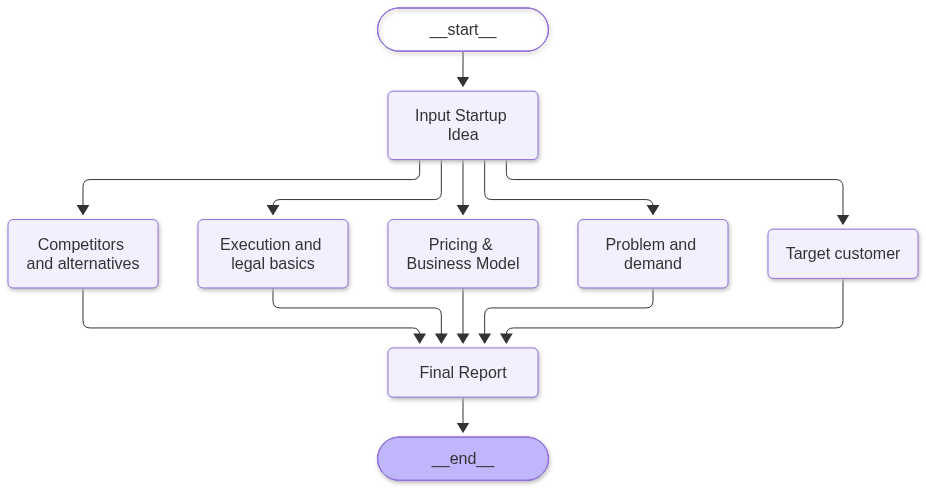

In [94]:
graph = workflow.compile()
graph

In [97]:
res = graph.invoke({})

RateLimitError: Error code: 429 - {'error': {'message': 'Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m7cpm839ehxv4dc0qmvv1pxv` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 7909, Requested 3175. Please try again in 23.13s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

In [102]:
print(res["final_report"])

            Startup ANALYSIS

1. PROBLEM AND DEMAND
## Research Report  
**Topic:** *An AI‑powered GST & Invoice Reconciliation Copilot for Indian MSMEs*  
**Focus:** Problem landscape & market demand (as of FY 2025‑26)  

---

### 1. Executive Summary  

- **Problem:** Indian micro‑, small‑ and medium‑enterprises (MSMEs) spend ≈ 30‑40 % of their finance & admin head‑count on GST compliance and invoice reconciliation. Errors cost the sector **₹ 2,200 cr–₹ 3,500 cr** annually in penalties, interest, and working‑capital strain.  
- **Demand:** 75 % of MSMEs (≈ 1.2 crore firms) indicate willingness to adopt an AI‑driven “copilot” that can (i) auto‑extract data from invoices, (ii) match purchase‑sale ledgers against GST returns, and (iii) flag mismatches in real‑time.  
- **Opportunity:** A SaaS‑based AI copilot priced at **₹ 1,200–2,500 per month** could capture **≈ 12 %** of the addressable market within 3 years, delivering a TAM of **₹ 6,000 cr** and a 5‑year ARR of **₹ 1,200 cr**.  

-